# Mean values

# Annual

Extracting global temperature data...
Reading global temperature data...
  126: 5 values
  585: 5 values

Extracting regional data for all variables...
Reading T from Tas_gap_annual2_rev1.xlsx...
  Processed T for 2 regions
Reading Prw from PrecipWa_gap_annual2_rev1.xlsx...
  Processed Prw for 2 regions
Reading Pr from Precip_gap_annual2_rev1.xlsx...
  Processed Pr for 2 regions
Reading E from Evaporation_gap_annual2_rev1.xlsx...
  Processed E for 2 regions
Reading SM from SM_gap_annual2_rev1.xlsx...
  Processed SM for 2 regions
Reading q from Runoff_gap_annual2_rev1.xlsx...
  Processed q for 2 regions

Creating global temperature plot...
Creating right subplot — Global & Tropics...

Time period: Midterm (2021-2050)
Regions shown: Global, Tropics
Saved as: global_tropics_annual_midterm.png


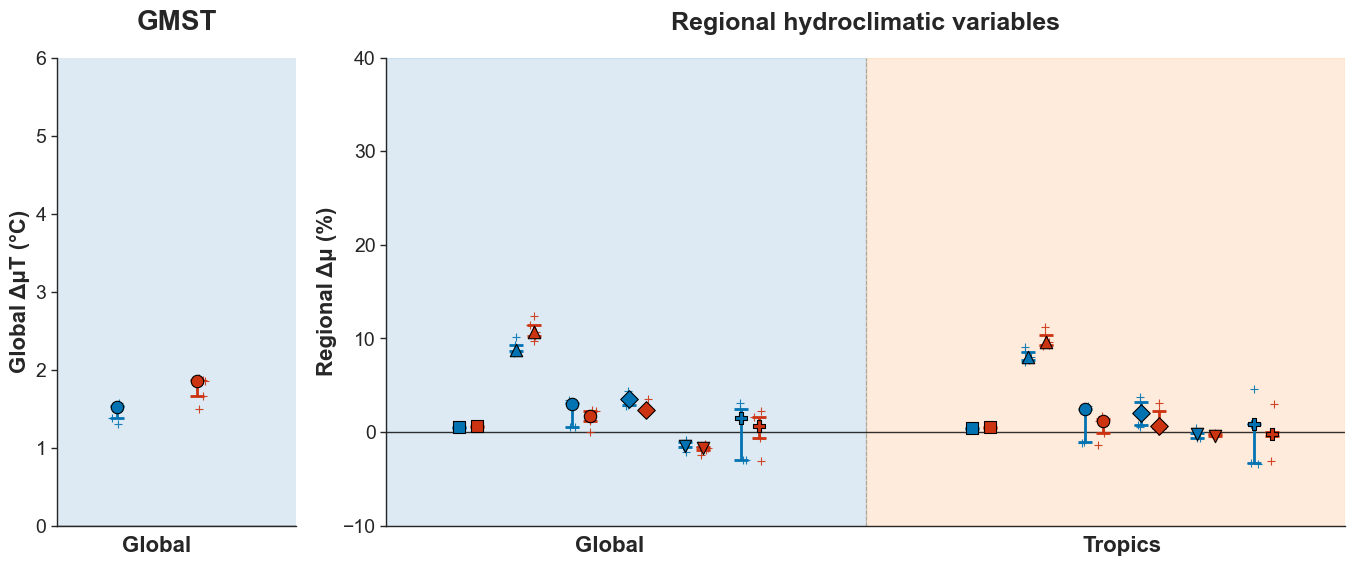

In [1]:
# Global and Tropics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from matplotlib.lines import Line2D

# === Configure Nature journal aesthetics ===
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 16,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'lines.linewidth': 1.2,
    'patch.linewidth': 1.0,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'text.usetex': False,
})

plt.style.use('default')
sns.set_style("white")

# === Configuration ===
TIME_PERIOD = "Midterm"  # Options: "Midterm" (2021-2050) or "Longterm" (2071-2100)

# Regions shown in right subplot
SELECTED_REGIONS = ['Global', 'Tropics']

# === File and variable setup ===
variables = {
    "T":   "Tas_gap_annual2_rev1.xlsx",
    "Prw": "PrecipWa_gap_annual2_rev1.xlsx",
    "Pr":  "Precip_gap_annual2_rev1.xlsx",
    "E":   "Evaporation_gap_annual2_rev1.xlsx",
    "SM":  "SM_gap_annual2_rev1.xlsx",
    "q":   "Runoff_gap_annual2_rev1.xlsx"
}

# === Scenario colors ===
scenario_colors = {
    '126': '#0173B2',
    '585': '#CC3311'
}

# === Region display name mapping ===
region_display_names = {
    'Global':          'Global',
    'Tropics':         'Tropics',
    'Subtropics_N':    'Northern Subtropics',
    'Subtropics_S':    'Southern Subtropics',
    'Mid_Latitudes_N': 'Northern Midlatitudes',
    'Mid_Latitudes_S': 'Southern Midlatitudes'
}

# ADD THIS HERE
region_bg_colors = {
    'Global':          '#1f77b4',
    'Tropics':         '#ff7f0e',
    'Subtropics_N':    '#2ca02c',
    'Subtropics_S':    '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

regional_order = SELECTED_REGIONS

# === Dynamic column naming ===
temp_col_126 = f'126_{TIME_PERIOD}_ºK'
temp_col_585 = f'585_{TIME_PERIOD}_ºK'
pct_col_126  = f'126_{TIME_PERIOD}_%'
pct_col_585  = f'585_{TIME_PERIOD}_%'

period_labels = {"Midterm": "(2021-2050)", "Longterm": "(2071-2100)"}
period_label  = period_labels.get(TIME_PERIOD, "")

# ============================================================
# === Extract global temperature data (in °C) — left subplot
# ============================================================
def extract_global_temperature():
    temp_data = {'126': [], '585': []}
    try:
        print("Reading global temperature data...")
        df = pd.read_excel("Tas_gap_annual2_rev1.xlsx", sheet_name='Sheet1')
        global_rows = df[df['Regions'].str.lower() == 'global']
        if temp_col_126 in df.columns:
            temp_data['126'] = global_rows[temp_col_126].dropna().tolist()
        if temp_col_585 in df.columns:
            temp_data['585'] = global_rows[temp_col_585].dropna().tolist()
        print(f"  126: {len(temp_data['126'])} values")
        print(f"  585: {len(temp_data['585'])} values")
    except Exception as e:
        print(f"Error reading temperature data: {e}")
    return temp_data

# ============================================================
# === Extract regional data for all variables (in %)
# ============================================================
def extract_regional_data():
    regional_data = {'126': {}, '585': {}}
    for scenario in ['126', '585']:
        regional_data[scenario] = {}
        for var in variables.keys():
            regional_data[scenario][var] = {}
            for region in regional_order:
                regional_data[scenario][var][region] = []

    for var_name, file_path in variables.items():
        try:
            print(f"Reading {var_name} from {file_path}...")
            df = pd.read_excel(file_path, sheet_name='Sheet1')
            for region in regional_order:
                if region.lower() == 'global':
                    region_rows = df[df['Regions'].str.lower() == 'global']
                else:
                    region_rows = df[df['Regions'] == region]
                if not region_rows.empty:
                    if pct_col_126 in df.columns:
                        regional_data['126'][var_name][region] = region_rows[pct_col_126].dropna().tolist()
                    if pct_col_585 in df.columns:
                        regional_data['585'][var_name][region] = region_rows[pct_col_585].dropna().tolist()
            print(f"  Processed {var_name} for {len(regional_order)} regions")
        except Exception as e:
            print(f"Error reading {file_path}: {e}")
    return regional_data

# === Extract data ===
print("Extracting global temperature data...")
global_temp_data = extract_global_temperature()

print("\nExtracting regional data for all variables...")
regional_data = extract_regional_data()

# ============================================================
# === Layout parameters for right subplot
# ============================================================
var_names  = ["T", "Prw", "Pr", "E", "SM", "q"]
var_labels = ["ΔT", "ΔPrw", "ΔPr", "ΔE", "ΔSM", "Δq"]
n_vars     = len(var_names)
n_regions  = len(SELECTED_REGIONS)

# Marker styles per variable
var_markers = {
    "T":   "s",
    "Prw": "^",
    "Pr":  "o",
    "E":   "D",
    "SM":  "v",
    "q":   "P",
}

# Spacing — region_gap must exceed total_var_span
scen_offset    = 0.07
var_spacing    = 0.22
region_gap     = 2.0

region_centers  = [i * region_gap for i in range(n_regions)]
total_var_span  = (n_vars - 1) * var_spacing
var_offsets     = [j * var_spacing - total_var_span / 2.0 for j in range(n_vars)]

# ============================================================
# === Helper: IQR summary statistics
# ============================================================
def iqr_stats(data):
    arr = np.array(data, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan, np.nan, np.nan
    return np.median(arr), np.percentile(arr, 25), np.percentile(arr, 75)

# ============================================================
# === Create figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),
                                gridspec_kw={'width_ratios': [1, 4]})

# ============================================================
# === Plot 1: Global Temperature (Left subplot) — marker + IQR errorbar
# ============================================================
print("\nCreating global temperature plot...")

for scen_idx, scen in enumerate(['126', '585']):
    data = global_temp_data[scen]
    if not data:
        continue
    med, q25, q75 = iqr_stats(data)
    color = scenario_colors[scen]
    x_pos = scen_idx * 0.4

    arr    = np.array(data, dtype=float)
    jitter = np.random.normal(x_pos, 0.015, len(arr))
    ax1.scatter(jitter, arr, marker='+', color=color, s=40,
                alpha=0.9, linewidths=0.8, zorder=2)

    ax1.errorbar(x_pos, med,
                 yerr=[[med - q25], [q75 - med]],
                 fmt='none', ecolor=color, elinewidth=2.0,
                 capsize=5, capthick=2.0, zorder=4)

    ax1.scatter(x_pos, med, color=color, marker='o',
                s=80, zorder=5, edgecolors='black', linewidths=0.8)

ax1.set_ylim(0, 6.0)
ax1.set_xlim(-0.3, 0.9)
ax1.set_xticks([0.2])
ax1.set_xticklabels(['Global'], fontsize=16, fontweight='bold')
ax1.set_xlabel('')
ax1.set_title('GMST', fontsize=20, fontweight='bold', pad=20)
ax1.set_ylabel('Global ΔμT (°C)', fontsize=16, fontweight='bold')
ax1.tick_params(axis='y', labelsize=14)
ax1.set_ylim(bottom=0)
ax1.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.0)
ax1.spines['bottom'].set_linewidth(1.0)
ax1.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax1.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax1.grid(False)
ax1.set_facecolor((*mpl.colors.to_rgb('#1f77b4'), 0.15))

# ============================================================
# === Plot 2: Right subplot — Global & Tropics, grouped by variable
# ============================================================
print("Creating right subplot — Global & Tropics...")

region_label_positions = []

half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25

for reg_idx, region in enumerate(SELECTED_REGIONS):
    reg_center = region_centers[reg_idx]
    region_label_positions.append(reg_center)

    # ADD THIS HERE
    bg_color = region_bg_colors.get(region, 'gray')
    x_left  = reg_center - region_gap / 2.0 if reg_idx > 0 else region_centers[0] - half_group
    x_right = reg_center + region_gap / 2.0 if reg_idx < n_regions - 1 else region_centers[-1] + half_group
    ax2.axvspan(x_left, x_right, color=bg_color, alpha=0.15, zorder=0)

    #for var_idx, var in enumerate(var_names):
    #    var_slot_center = reg_center + var_offsets[var_idx]
    #    var_tick_positions_all.append(var_slot_center)
    #    var_tick_labels_all.append(var_labels[var_idx])

    for var_idx, var in enumerate(var_names):
        var_slot_center = reg_center + var_offsets[var_idx]

        for scen_idx, scen in enumerate(['126', '585']):
            data = regional_data[scen].get(var, {}).get(region, [])
            if not data:
                continue

            color  = scenario_colors[scen]
            marker = var_markers[var]
            x_pos  = var_slot_center + (scen_idx - 0.5) * scen_offset

            arr = np.array(data, dtype=float)
            arr = arr[~np.isnan(arr)]
            med, q25, q75 = iqr_stats(arr)

            # Faint individual model runs
            jitter = np.random.normal(x_pos, 0.008, len(arr))
            ax2.scatter(jitter, arr, marker='+', color=color, s=40,
                        alpha=0.90, linewidths=0.8, zorder=1)

            # IQR error bar
            ax2.errorbar(x_pos, med,
                         yerr=[[med - q25], [q75 - med]],
                         fmt='none', ecolor=color, elinewidth=2.0,
                         capsize=5, capthick=2.0, zorder=3)

            # Median marker
            ax2.scatter(x_pos, med, color=color, marker=marker,
                        s=80, zorder=4, edgecolors='black', linewidths=0.8)

# --- Primary x-ticks: region names ---
ax2.set_xticks(region_label_positions)
ax2.set_xticklabels(
    [region_display_names.get(r, r) for r in SELECTED_REGIONS],
    fontsize=16, fontweight='bold'
)

# --- Force equal x-axis padding for both regions ---
#half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25
ax2.set_xlim(region_centers[0] - half_group,
             region_centers[-1] + half_group)

# --- Vertical dashed separator between regions ---
for reg_idx in range(n_regions - 1):
    sep_x = (region_centers[reg_idx] + region_centers[reg_idx + 1]) / 2.0
    ax2.axvline(sep_x, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=0)

ax2.set_ylim(-10, 40)
ax2.set_title('Regional hydroclimatic variables', fontsize=18, fontweight='bold', pad=20)
ax2.set_ylabel('Regional Δμ (%)', fontsize=16, fontweight='bold')
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=16)
ax2.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(1.0)
ax2.spines['bottom'].set_linewidth(1.0)
ax2.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax2.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax2.grid(False)

# ============================================================
# === Legend — one row below figure
# ============================================================
legend_scenario = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['126'],
           markeredgecolor='black', markersize=9, label='SSP1-2.6'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['585'],
           markeredgecolor='black', markersize=9, label='SSP5-8.5'),
]
legend_vars = [
    Line2D([0], [0], marker=var_markers[v], color='w', markerfacecolor='gray',
           markeredgecolor='black', markersize=8, label=var_labels[i])
    for i, v in enumerate(var_names)
]

plt.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.14, wspace=0.15)

#fig.legend(handles=legend_scenario + legend_vars,
#           loc='lower center',
#           bbox_to_anchor=(0.5, 0.01),
#           ncol=len(legend_scenario) + len(legend_vars),
#           fontsize=11,
#           frameon=True, framealpha=0.9, edgecolor='gray',
#           handletextpad=0.4, columnspacing=1.0)

# ============================================================
# === Save
# ============================================================
filename_base = f"global_tropics_annual_{TIME_PERIOD.lower()}.png"
plt.savefig(filename_base, dpi=800, bbox_inches='tight',
            facecolor='white', edgecolor='none')

print(f"\nTime period: {TIME_PERIOD} {period_label}")
print(f"Regions shown: {', '.join(SELECTED_REGIONS)}")
print(f"Saved as: {filename_base}")

plt.show()

Extracting global temperature data...
Reading global temperature data...
  126: 5 values
  585: 5 values

Extracting regional data for all variables...
Reading T from Tas_gap_annual2_rev1.xlsx...
  Processed T for 4 regions
Reading Prw from PrecipWa_gap_annual2_rev1.xlsx...
  Processed Prw for 4 regions
Reading Pr from Precip_gap_annual2_rev1.xlsx...
  Processed Pr for 4 regions
Reading E from Evaporation_gap_annual2_rev1.xlsx...
  Processed E for 4 regions
Reading SM from SM_gap_annual2_rev1.xlsx...
  Processed SM for 4 regions
Reading q from Runoff_gap_annual2_rev1.xlsx...
  Processed q for 4 regions

Creating global temperature plot...
Creating right subplot — NSZ, SSZ, NMZ, SMZ...

Time period: Longterm (2071-2100)
Regions shown: Northern Subtropics, Southern Subtropics, Northern Midlatitudes, Southern Midlatitudes
Saved as: 4regions_markerplot_annual_longterm.png


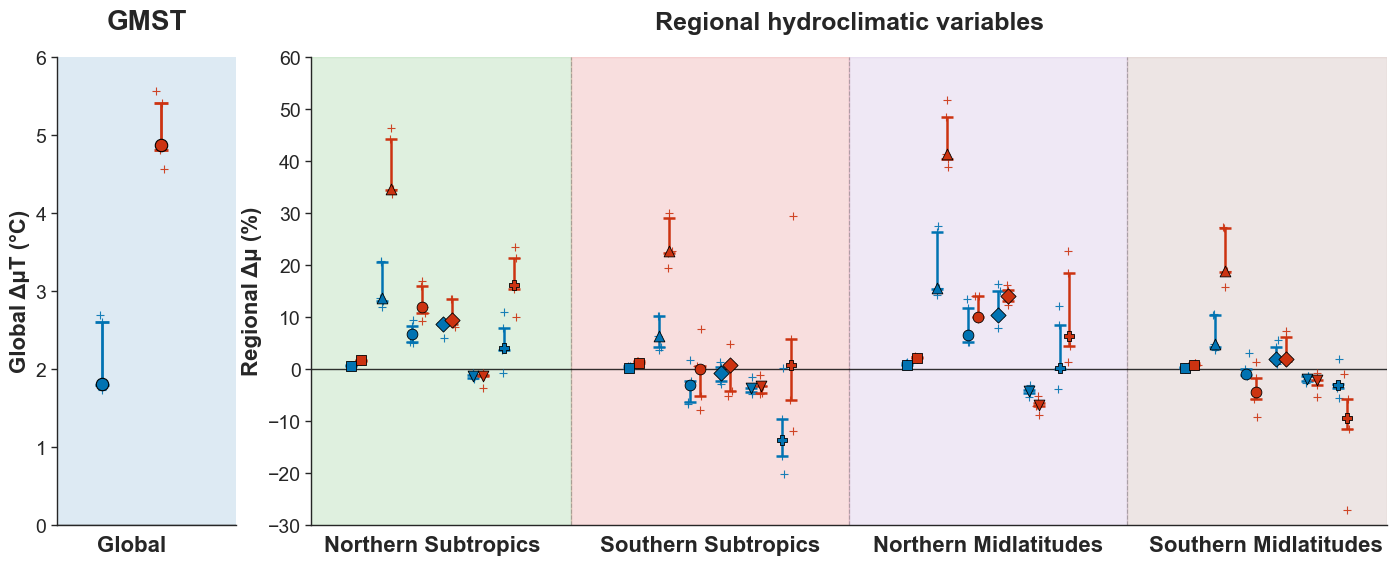

In [36]:
# Global and Subtropics/Midlatitudes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from matplotlib.lines import Line2D

# === Configure Nature journal aesthetics ===
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 16,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'lines.linewidth': 1.2,
    'patch.linewidth': 1.0,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'text.usetex': False,
})

plt.style.use('default')
sns.set_style("white")

# === Configuration ===
TIME_PERIOD = "Longterm"  # Options: "Midterm" (2021-2050) or "Longterm" (2071-2100)

# Regions shown in right subplot
SELECTED_REGIONS = ['Subtropics_N', 'Subtropics_S', 'Mid_Latitudes_N', 'Mid_Latitudes_S']

# === File and variable setup ===
variables = {
    "T":   "Tas_gap_annual2_rev1.xlsx",
    "Prw": "PrecipWa_gap_annual2_rev1.xlsx",
    "Pr":  "Precip_gap_annual2_rev1.xlsx",
    "E":   "Evaporation_gap_annual2_rev1.xlsx",
    "SM":  "SM_gap_annual2_rev1.xlsx",
    "q":   "Runoff_gap_annual2_rev1.xlsx"
}

# === Scenario colors ===
scenario_colors = {
    '126': '#0173B2',
    '585': '#CC3311'
}

# === Region display name mapping ===
region_display_names = {
    'Global':          'Global',
    'Tropics':         'Tropics',
    'Subtropics_N':    'Northern Subtropics',
    'Subtropics_S':    'Southern Subtropics',
    'Mid_Latitudes_N': 'Northern Midlatitudes',
    'Mid_Latitudes_S': 'Southern Midlatitudes'
}

region_bg_colors = {
    'Global':          '#1f77b4',
    'Tropics':         '#ff7f0e',
    'Subtropics_N':    '#2ca02c',
    'Subtropics_S':    '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

regional_order = SELECTED_REGIONS

# === Dynamic column naming ===
temp_col_126 = f'126_{TIME_PERIOD}_ºK'
temp_col_585 = f'585_{TIME_PERIOD}_ºK'
pct_col_126  = f'126_{TIME_PERIOD}_%'
pct_col_585  = f'585_{TIME_PERIOD}_%'

period_labels = {"Midterm": "(2021-2050)", "Longterm": "(2071-2100)"}
period_label  = period_labels.get(TIME_PERIOD, "")

# ============================================================
# === Extract global temperature data (in °C) — left subplot
# ============================================================
def extract_global_temperature():
    temp_data = {'126': [], '585': []}
    try:
        print("Reading global temperature data...")
        df = pd.read_excel("Tas_gap_annual2_rev1.xlsx", sheet_name='Sheet1')
        global_rows = df[df['Regions'].str.lower() == 'global']
        if temp_col_126 in df.columns:
            temp_data['126'] = global_rows[temp_col_126].dropna().tolist()
        if temp_col_585 in df.columns:
            temp_data['585'] = global_rows[temp_col_585].dropna().tolist()
        print(f"  126: {len(temp_data['126'])} values")
        print(f"  585: {len(temp_data['585'])} values")
    except Exception as e:
        print(f"Error reading temperature data: {e}")
    return temp_data

# ============================================================
# === Extract regional data for all variables (in %)
# ============================================================
def extract_regional_data():
    regional_data = {'126': {}, '585': {}}
    for scenario in ['126', '585']:
        regional_data[scenario] = {}
        for var in variables.keys():
            regional_data[scenario][var] = {}
            for region in regional_order:
                regional_data[scenario][var][region] = []

    for var_name, file_path in variables.items():
        try:
            print(f"Reading {var_name} from {file_path}...")
            df = pd.read_excel(file_path, sheet_name='Sheet1')
            for region in regional_order:
                if region.lower() == 'global':
                    region_rows = df[df['Regions'].str.lower() == 'global']
                else:
                    region_rows = df[df['Regions'] == region]
                if not region_rows.empty:
                    if pct_col_126 in df.columns:
                        regional_data['126'][var_name][region] = region_rows[pct_col_126].dropna().tolist()
                    if pct_col_585 in df.columns:
                        regional_data['585'][var_name][region] = region_rows[pct_col_585].dropna().tolist()
            print(f"  Processed {var_name} for {len(regional_order)} regions")
        except Exception as e:
            print(f"Error reading {file_path}: {e}")
    return regional_data

# === Extract data ===
print("Extracting global temperature data...")
global_temp_data = extract_global_temperature()

print("\nExtracting regional data for all variables...")
regional_data = extract_regional_data()

# ============================================================
# === Layout parameters for right subplot
# ============================================================
var_names  = ["T", "Prw", "Pr", "E", "SM", "q"]
var_labels = ["ΔT", "ΔPrw", "ΔPr", "ΔE", "ΔSM", "Δq"]
n_vars     = len(var_names)
n_regions  = len(SELECTED_REGIONS)

# Marker styles per variable
var_markers = {
    "T":   "s",
    "Prw": "^",
    "Pr":  "o",
    "E":   "D",
    "SM":  "v",
    "q":   "P",
}

# Spacing
scen_offset    = 0.07
var_spacing    = 0.22
region_gap     = 2.0

region_centers  = [i * region_gap for i in range(n_regions)]
total_var_span  = (n_vars - 1) * var_spacing
var_offsets     = [j * var_spacing - total_var_span / 2.0 for j in range(n_vars)]

# Compute half_group BEFORE the plotting loop (was the source of the NameError)
half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25

# ============================================================
# === Helper: IQR summary statistics
# ============================================================
def iqr_stats(data):
    arr = np.array(data, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan, np.nan, np.nan
    return np.median(arr), np.percentile(arr, 25), np.percentile(arr, 75)

# ============================================================
# === Create figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),
                                gridspec_kw={'width_ratios': [1, 6]})

# ============================================================
# === Plot 1: Global Temperature (Left subplot) — marker + IQR errorbar
# ============================================================
print("\nCreating global temperature plot...")

for scen_idx, scen in enumerate(['126', '585']):
    data = global_temp_data[scen]
    if not data:
        continue
    med, q25, q75 = iqr_stats(data)
    color = scenario_colors[scen]
    x_pos = scen_idx * 0.4

    arr    = np.array(data, dtype=float)
    jitter = np.random.normal(x_pos, 0.015, len(arr))
    ax1.scatter(jitter, arr, marker='+', color=color, s=40,
                alpha=0.9, linewidths=0.8, zorder=2)

    ax1.errorbar(x_pos, med,
                 yerr=[[med - q25], [q75 - med]],
                 fmt='none', ecolor=color, elinewidth=2.0,
                 capsize=5, capthick=2.0, zorder=4)

    ax1.scatter(x_pos, med, color=color, marker='o',
                s=80, zorder=5, edgecolors='black', linewidths=0.8)

ax1.set_ylim(0, 6.0)
ax1.set_xlim(-0.3, 0.9)
ax1.set_xticks([0.2])
ax1.set_xticklabels(['Global'], fontsize=16, fontweight='bold')
ax1.set_xlabel('')
ax1.set_title('GMST', fontsize=20, fontweight='bold', pad=20)
ax1.set_ylabel('Global ΔμT (°C)', fontsize=16, fontweight='bold')
ax1.tick_params(axis='y', labelsize=14)
ax1.set_ylim(bottom=0)
ax1.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.0)
ax1.spines['bottom'].set_linewidth(1.0)
ax1.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax1.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax1.grid(False)
ax1.set_facecolor((*mpl.colors.to_rgb('#1f77b4'), 0.15))

# ============================================================
# === Plot 2: Right subplot — NSZ, SSZ, NMZ, SMZ
# ============================================================

print("Creating right subplot — NSZ, SSZ, NMZ, SMZ...")

half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25  # move this up here

# Collect x-tick info
region_label_positions = []   # centre of each region group (for x-tick labels)
var_tick_positions_all = []   # position of each var within each region (for minor ticks)
var_tick_labels_all    = []

for reg_idx, region in enumerate(SELECTED_REGIONS):
    reg_center = region_centers[reg_idx]
    region_label_positions.append(reg_center)

    # Background band per region — half_group is now defined above
    bg_color = region_bg_colors.get(region, 'gray')
    x_left  = reg_center - region_gap / 2.0 if reg_idx > 0 else region_centers[0]  - half_group
    x_right = reg_center + region_gap / 2.0 if reg_idx < n_regions - 1 else region_centers[-1] + half_group
    ax2.axvspan(x_left, x_right, color=bg_color, alpha=0.15, zorder=0)

    for var_idx, var in enumerate(var_names):
        var_slot_center = reg_center + var_offsets[var_idx]
        var_tick_positions_all.append(var_slot_center)
        var_tick_labels_all.append(var_labels[var_idx])

        for scen_idx, scen in enumerate(['126', '585']):
            data = regional_data[scen].get(var, {}).get(region, [])
            if not data:
                continue

            color  = scenario_colors[scen]
            marker = var_markers[var]
            # SSP1-2.6 slightly left, SSP5-8.5 slightly right
            x_pos  = var_slot_center + (scen_idx - 0.5) * scen_offset

            arr = np.array(data, dtype=float)
            arr = arr[~np.isnan(arr)]
            med, q25, q75 = iqr_stats(arr)

            # Faint individual model runs as '+' in background
            jitter = np.random.normal(x_pos, 0.008, len(arr))
            ax2.scatter(jitter, arr, marker='+', color=color, s=40,
                        alpha=0.90, linewidths=0.8, zorder=1)

            # IQR error bar
            ax2.errorbar(x_pos, med,
                         yerr=[[med - q25], [q75 - med]],
                         fmt='none',
                         ecolor=color, elinewidth=1.8,
                         capsize=4, capthick=1.8, zorder=3)

            # Median marker
            ax2.scatter(x_pos, med, color=color, marker=marker,
                        s=60, zorder=4, edgecolors='black', linewidths=0.6)


# --- Primary x-ticks: region names ---
ax2.set_xticks(region_label_positions)
ax2.set_xticklabels(
    [region_display_names.get(r, r) for r in SELECTED_REGIONS],
    fontsize=16, fontweight='bold'
)

ax2.set_xlim(region_centers[0] - half_group,
             region_centers[-1] + half_group)

# --- Vertical dashed separators between region groups ---
for reg_idx in range(n_regions - 1):
    sep_x = (region_centers[reg_idx] + region_centers[reg_idx + 1]) / 2.0
    ax2.axvline(sep_x, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=0)

# --- Legend: scenarios (color) + variables (marker shape) — placed below figure ---
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_scenario = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['126'],
           markeredgecolor='black', markersize=9, label='SSP1-2.6'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['585'],
           markeredgecolor='black', markersize=9, label='SSP5-8.5'),
]
legend_vars = [
    Line2D([0], [0], marker=var_markers[v], color='w', markerfacecolor='gray',
           markeredgecolor='black', markersize=8, label=v)
    for v in var_names
]

ax2.set_ylim(-30, 60)
ax2.set_title('Regional hydroclimatic variables', fontsize=18, fontweight='bold', pad=20)
ax2.set_ylabel('Regional Δμ (%)', fontsize=16, fontweight='bold')
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=16)
ax2.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(1.0)
ax2.spines['bottom'].set_linewidth(1.0)
ax2.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax2.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax2.grid(False)


plt.subplots_adjust(left=0.04, right=0.99, top=0.88, bottom=0.1, wspace=0.12)

# ============================================================
# === Save
# ============================================================

filename_base = f"4regions_markerplot_annual_{TIME_PERIOD.lower()}.png"
plt.savefig(filename_base, dpi=800, bbox_inches='tight',
            facecolor='white', edgecolor='none')

print(f"\nTime period: {TIME_PERIOD} {period_label}")
print(f"Regions shown: {', '.join([region_display_names.get(r,r) for r in SELECTED_REGIONS])}")
print(f"Saved as: {filename_base}")

plt.show()

# Standard Deviation

Extracting global temperature data...
Reading global temperature data...
  126: 5 values
  585: 5 values

Extracting regional data for all variables...
Reading T from Tas_gap_annual2_std_rev1.xlsx...
  Processed T for 2 regions
Reading Prw from PrecipWa_gap_annual2_std_rev1.xlsx...
  Processed Prw for 2 regions
Reading Pr from Precip_gap_annual2_std_rev1.xlsx...
  Processed Pr for 2 regions
Reading ET from Evaporation_gap_annual2_std_rev1.xlsx...
  Processed ET for 2 regions
Reading SM from SM_gap_annual2_std_rev1.xlsx...
  Processed SM for 2 regions
Reading q from Runoff_gap_annual2_std_rev1.xlsx...
  Processed q for 2 regions

Creating global temperature plot...
Creating right subplot — Global & Tropics...

Time period: Longterm (2071-2100)
Regions shown: Global, Tropics
Saved as: global_tropics_annual_std_longterm.png


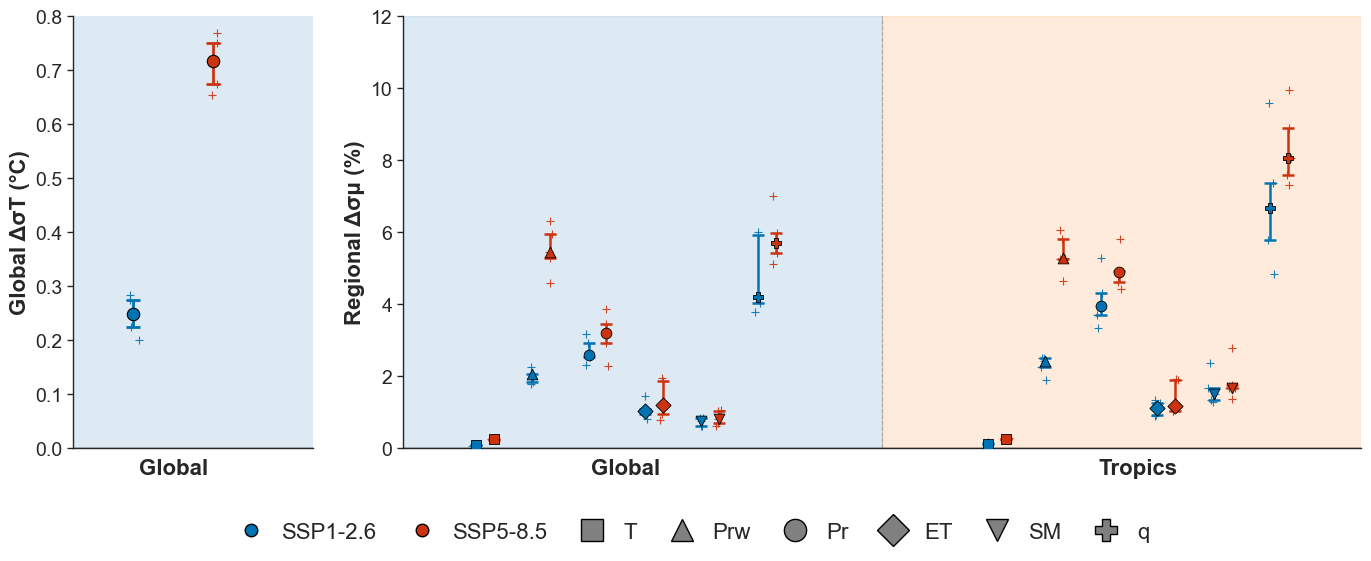

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from matplotlib.lines import Line2D

# === Configure Nature journal aesthetics ===
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 16,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'lines.linewidth': 1.2,
    'patch.linewidth': 1.0,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'text.usetex': False,
})

plt.style.use('default')
sns.set_style("white")

# === Configuration ===
TIME_PERIOD = "Longterm"  # Options: "Midterm" (2021-2050) or "Longterm" (2071-2100)

# Regions shown in right subplot
SELECTED_REGIONS = ['Global', 'Tropics']

# === File and variable setup ===
variables = {
    "T":   "Tas_gap_annual2_std_rev1.xlsx",
    "Prw": "PrecipWa_gap_annual2_std_rev1.xlsx",
    "Pr":  "Precip_gap_annual2_std_rev1.xlsx",
    "ET":   "Evaporation_gap_annual2_std_rev1.xlsx",
    "SM":  "SM_gap_annual2_std_rev1.xlsx",
    "q":   "Runoff_gap_annual2_std_rev1.xlsx"
}

# === Scenario colors ===
scenario_colors = {
    '126': '#0173B2',
    '585': '#CC3311'
}

# === Region display name mapping ===
region_display_names = {
    'Global':          'Global',
    'Tropics':         'Tropics',
    'Subtropics_N':    'Northern Subtropics',
    'Subtropics_S':    'Southern Subtropics',
    'Mid_Latitudes_N': 'Northern Midlatitudes',
    'Mid_Latitudes_S': 'Southern Midlatitudes'
}

# ADD THIS HERE
region_bg_colors = {
    'Global':          '#1f77b4',
    'Tropics':         '#ff7f0e',
    'Subtropics_N':    '#2ca02c',
    'Subtropics_S':    '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

regional_order = SELECTED_REGIONS

# === Dynamic column naming ===
temp_col_126 = f'126_{TIME_PERIOD}_ºK'
temp_col_585 = f'585_{TIME_PERIOD}_ºK'
pct_col_126  = f'126_{TIME_PERIOD}_%'
pct_col_585  = f'585_{TIME_PERIOD}_%'

period_labels = {"Midterm": "(2021-2050)", "Longterm": "(2071-2100)"}
period_label  = period_labels.get(TIME_PERIOD, "")

# ============================================================
# === Extract global temperature data (in °C) — left subplot
# ============================================================
def extract_global_temperature():
    temp_data = {'126': [], '585': []}
    try:
        print("Reading global temperature data...")
        df = pd.read_excel("Tas_gap_annual2_std_rev1.xlsx", sheet_name='Sheet1')
        global_rows = df[df['Regions'].str.lower() == 'global']
        if temp_col_126 in df.columns:
            temp_data['126'] = global_rows[temp_col_126].dropna().tolist()
        if temp_col_585 in df.columns:
            temp_data['585'] = global_rows[temp_col_585].dropna().tolist()
        print(f"  126: {len(temp_data['126'])} values")
        print(f"  585: {len(temp_data['585'])} values")
    except Exception as e:
        print(f"Error reading temperature data: {e}")
    return temp_data

# ============================================================
# === Extract regional data for all variables (in %)
# ============================================================
def extract_regional_data():
    regional_data = {'126': {}, '585': {}}
    for scenario in ['126', '585']:
        regional_data[scenario] = {}
        for var in variables.keys():
            regional_data[scenario][var] = {}
            for region in regional_order:
                regional_data[scenario][var][region] = []

    for var_name, file_path in variables.items():
        try:
            print(f"Reading {var_name} from {file_path}...")
            df = pd.read_excel(file_path, sheet_name='Sheet1')
            for region in regional_order:
                if region.lower() == 'global':
                    region_rows = df[df['Regions'].str.lower() == 'global']
                else:
                    region_rows = df[df['Regions'] == region]
                if not region_rows.empty:
                    if pct_col_126 in df.columns:
                        regional_data['126'][var_name][region] = region_rows[pct_col_126].dropna().tolist()
                    if pct_col_585 in df.columns:
                        regional_data['585'][var_name][region] = region_rows[pct_col_585].dropna().tolist()
            print(f"  Processed {var_name} for {len(regional_order)} regions")
        except Exception as e:
            print(f"Error reading {file_path}: {e}")
    return regional_data

# === Extract data ===
print("Extracting global temperature data...")
global_temp_data = extract_global_temperature()

print("\nExtracting regional data for all variables...")
regional_data = extract_regional_data()

# ============================================================
# === Layout parameters for right subplot
# ============================================================
var_names  = ["T", "Prw", "Pr", "ET", "SM", "q"]
var_labels = ["ΔT", "ΔPrw", "ΔPr", "ΔET", "ΔSM", "Δq"]
n_vars     = len(var_names)
n_regions  = len(SELECTED_REGIONS)

# Marker styles per variable
var_markers = {
    "T":   "s",
    "Prw": "^",
    "Pr":  "o",
    "ET":   "D",
    "SM":  "v",
    "q":   "P",
}

# Spacing — region_gap must exceed total_var_span
scen_offset   = 0.07
var_spacing   = 0.22
region_gap    = 2.0

region_centers = [i * region_gap for i in range(n_regions)]
total_var_span = (n_vars - 1) * var_spacing
var_offsets    = [j * var_spacing - total_var_span / 2.0 for j in range(n_vars)]

# ============================================================
# === Helper: IQR summary statistics
# ============================================================
def iqr_stats(data):
    arr = np.array(data, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan, np.nan, np.nan
    return np.median(arr), np.percentile(arr, 25), np.percentile(arr, 75)

# ============================================================
# === Create figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),
                                gridspec_kw={'width_ratios': [1, 4]})

# ============================================================
# === Plot 1: Global Temperature (Left subplot) — marker + IQR errorbar
# ============================================================
print("\nCreating global temperature plot...")

for scen_idx, scen in enumerate(['126', '585']):
    data = global_temp_data[scen]
    if not data:
        continue
    med, q25, q75 = iqr_stats(data)
    color = scenario_colors[scen]
    x_pos = scen_idx * 0.4

    arr    = np.array(data, dtype=float)
    jitter = np.random.normal(x_pos, 0.015, len(arr))
    ax1.scatter(jitter, arr, marker='+', color=color, s=40,
                alpha=0.9, linewidths=0.8, zorder=2)

    ax1.errorbar(x_pos, med,
                 yerr=[[med - q25], [q75 - med]],
                 fmt='none', ecolor=color, elinewidth=2.0,
                 capsize=5, capthick=2.0, zorder=4)

    ax1.scatter(x_pos, med, color=color, marker='o',
                s=80, zorder=5, edgecolors='black', linewidths=0.8)

ax1.set_ylim(0, 0.8)
ax1.set_xlim(-0.3, 0.9)
ax1.set_xticks([0.2])
ax1.set_xticklabels(['Global'], fontsize=16, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Global ΔσT (°C)', fontsize=16, fontweight='bold')
ax1.tick_params(axis='y', labelsize=14)
ax1.set_ylim(bottom=0)
ax1.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.0)
ax1.spines['bottom'].set_linewidth(1.0)
ax1.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax1.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax1.grid(False)
ax1.set_facecolor((*mpl.colors.to_rgb('#1f77b4'), 0.15))

# ============================================================
# === Plot 2: Right subplot — Global & Tropics, grouped by variable
# ============================================================
print("Creating right subplot — Global & Tropics...")

region_label_positions = []

half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25

for reg_idx, region in enumerate(SELECTED_REGIONS):
    reg_center = region_centers[reg_idx]
    region_label_positions.append(reg_center)

    # ADD THIS HERE
    bg_color = region_bg_colors.get(region, 'gray')
    x_left  = reg_center - region_gap / 2.0 if reg_idx > 0 else region_centers[0] - half_group
    x_right = reg_center + region_gap / 2.0 if reg_idx < n_regions - 1 else region_centers[-1] + half_group
    ax2.axvspan(x_left, x_right, color=bg_color, alpha=0.15, zorder=0)

    for var_idx, var in enumerate(var_names):
        var_slot_center = reg_center + var_offsets[var_idx]

        for scen_idx, scen in enumerate(['126', '585']):
            data = regional_data[scen].get(var, {}).get(region, [])
            if not data:
                continue

            color  = scenario_colors[scen]
            marker = var_markers[var]
            x_pos  = var_slot_center + (scen_idx - 0.5) * scen_offset

            arr = np.array(data, dtype=float)
            arr = arr[~np.isnan(arr)]
            med, q25, q75 = iqr_stats(arr)

            # Faint individual model runs
            jitter = np.random.normal(x_pos, 0.008, len(arr))
            ax2.scatter(jitter, arr, marker='+', color=color, s=40,
                        alpha=0.90, linewidths=0.8, zorder=1)

            # IQR error bar
            ax2.errorbar(x_pos, med,
                         yerr=[[med - q25], [q75 - med]],
                         fmt='none', ecolor=color, elinewidth=1.8,
                         capsize=4, capthick=1.8, zorder=3)

            # Median marker
            ax2.scatter(x_pos, med, color=color, marker=marker,
                        s=60, zorder=4, edgecolors='black', linewidths=0.6)

# --- Primary x-ticks: region names ---
ax2.set_xticks(region_label_positions)
ax2.set_xticklabels(
    [region_display_names.get(r, r) for r in SELECTED_REGIONS],
    fontsize=16, fontweight='bold'
)

# --- Force equal x-axis padding for both regions ---
#half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25
ax2.set_xlim(region_centers[0] - half_group,
             region_centers[-1] + half_group)

# --- Vertical dashed separator between regions ---
for reg_idx in range(n_regions - 1):
    sep_x = (region_centers[reg_idx] + region_centers[reg_idx + 1]) / 2.0
    ax2.axvline(sep_x, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=0)

ax2.set_ylim(0, 12)
ax2.set_ylabel('Regional Δσμ (%)', fontsize=16, fontweight='bold')
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=16)
#ax2.set_ylim(bottom=0)
ax2.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(1.0)
ax2.spines['bottom'].set_linewidth(1.0)
ax2.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax2.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax2.grid(False)

# ============================================================
# === Legend — one row below figure
# ============================================================
legend_scenario = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['126'],
           markeredgecolor='black', markersize=9, label='SSP1-2.6'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['585'],
           markeredgecolor='black', markersize=9, label='SSP5-8.5'),
]
#legend_vars = [
#    Line2D([0], [0], marker=var_markers[v], color='w', markerfacecolor='gray',
#           markeredgecolor='black', markersize=8, label=var_labels[i])
#    for i, v in enumerate(var_names)
#]
legend_vars = [
    Line2D([0], [0], marker=var_markers[v], color='w', markerfacecolor='gray',
           markeredgecolor='black', markersize=16, label=v)
    for v in var_names
]

plt.subplots_adjust(left=0.06, right=0.98, top=0.92, bottom=0.2, wspace=0.15)

fig.legend(handles=legend_scenario + legend_vars,
           loc='lower center',
           bbox_to_anchor=(0.5, 0.01),
           ncol=len(legend_scenario) + len(legend_vars),
           fontsize=16,
           frameon=False, framealpha=0.9, edgecolor='gray',
           handletextpad=0.4, columnspacing=1.0)

# ============================================================
# === Save
# ============================================================
filename_base = f"global_tropics_annual_std_{TIME_PERIOD.lower()}.png"
plt.savefig(filename_base, dpi=800, bbox_inches='tight',
            facecolor='white', edgecolor='none')

print(f"\nTime period: {TIME_PERIOD} {period_label}")
print(f"Regions shown: {', '.join(SELECTED_REGIONS)}")
print(f"Saved as: {filename_base}")

plt.show()

Extracting global temperature data...
Reading global temperature data...
  126: 5 values
  585: 5 values

Extracting regional data for all variables...
Reading T from Tas_gap_annual2_std_rev1.xlsx...
  Processed T for 4 regions
Reading Prw from PrecipWa_gap_annual2_std_rev1.xlsx...
  Processed Prw for 4 regions
Reading Pr from Precip_gap_annual2_std_rev1.xlsx...
  Processed Pr for 4 regions
Reading ET from Evaporation_gap_annual2_std_rev1.xlsx...
  Processed ET for 4 regions
Reading SM from SM_gap_annual2_std_rev1.xlsx...
  Processed SM for 4 regions
Reading q from Runoff_gap_annual2_std_rev1.xlsx...
  Processed q for 4 regions

Creating global temperature plot...
Creating right subplot — NSZ, SSZ, NMZ, SMZ...

Time period: Longterm (2071-2100)
Regions shown: Northern Subtropics, Southern Subtropics, Northern Midlatitudes, Southern Midlatitudes
Saved as: 4regions_std_markerplot_annual_longterm.png


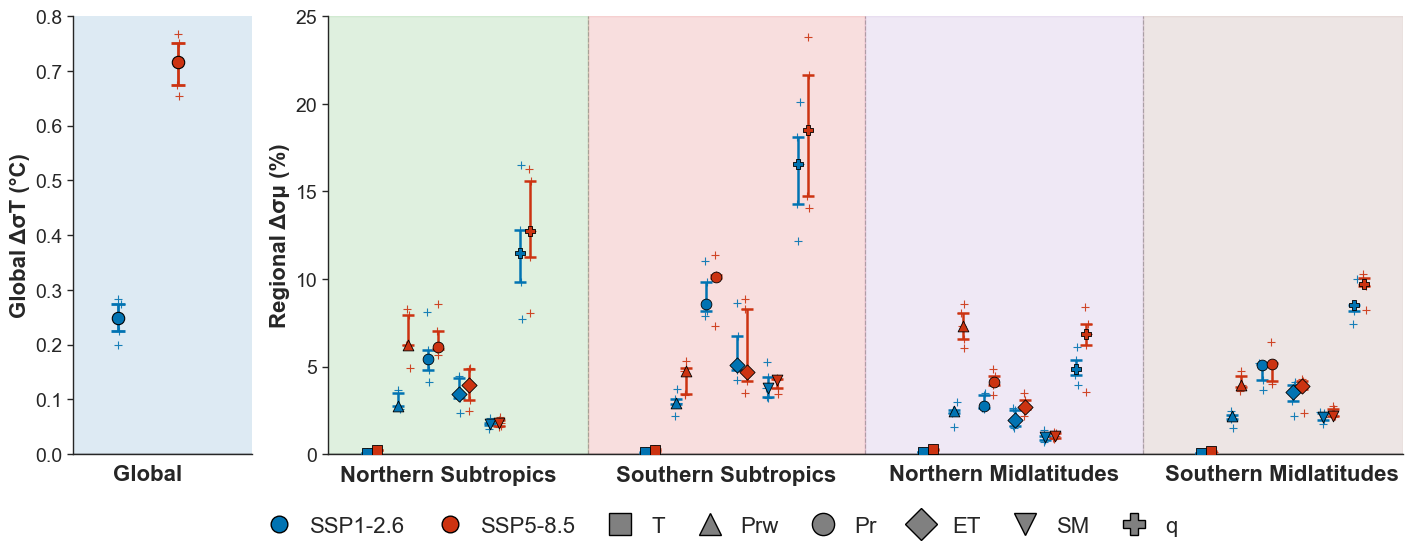

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from matplotlib.lines import Line2D

# === Configure Nature journal aesthetics ===
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 14,
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14,
    'figure.titlesize': 16,
    'axes.linewidth': 1.0,
    'xtick.major.width': 1.0,
    'ytick.major.width': 1.0,
    'lines.linewidth': 1.2,
    'patch.linewidth': 1.0,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'savefig.format': 'pdf',
    'text.usetex': False,
})

plt.style.use('default')
sns.set_style("white")

# === Configuration ===
TIME_PERIOD = "Longterm"  # Options: "Midterm" (2021-2050) or "Longterm" (2071-2100)

# Regions shown in right subplot
SELECTED_REGIONS = ['Subtropics_N', 'Subtropics_S', 'Mid_Latitudes_N', 'Mid_Latitudes_S']

# === File and variable setup ===
variables = {
    "T":   "Tas_gap_annual2_std_rev1.xlsx",
    "Prw": "PrecipWa_gap_annual2_std_rev1.xlsx",
    "Pr":  "Precip_gap_annual2_std_rev1.xlsx",
    "ET":   "Evaporation_gap_annual2_std_rev1.xlsx",
    "SM":  "SM_gap_annual2_std_rev1.xlsx",
    "q":   "Runoff_gap_annual2_std_rev1.xlsx"
}

# === Scenario colors ===
scenario_colors = {
    '126': '#0173B2',
    '585': '#CC3311'
}

# === Region display name mapping ===
region_display_names = {
    'Global':          'Global',
    'Tropics':         'Tropics',
    'Subtropics_N':    'Northern Subtropics',
    'Subtropics_S':    'Southern Subtropics',
    'Mid_Latitudes_N': 'Northern Midlatitudes',
    'Mid_Latitudes_S': 'Southern Midlatitudes'
}

region_bg_colors = {
    'Global':          '#1f77b4',
    'Tropics':         '#ff7f0e',
    'Subtropics_N':    '#2ca02c',
    'Subtropics_S':    '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

regional_order = SELECTED_REGIONS

# === Dynamic column naming ===
temp_col_126 = f'126_{TIME_PERIOD}_ºK'
temp_col_585 = f'585_{TIME_PERIOD}_ºK'
pct_col_126  = f'126_{TIME_PERIOD}_%'
pct_col_585  = f'585_{TIME_PERIOD}_%'

period_labels = {"Midterm": "(2021-2050)", "Longterm": "(2071-2100)"}
period_label  = period_labels.get(TIME_PERIOD, "")

# ============================================================
# === Extract global temperature data (in °C) — left subplot
# ============================================================
def extract_global_temperature():
    temp_data = {'126': [], '585': []}
    try:
        print("Reading global temperature data...")
        df = pd.read_excel("Tas_gap_annual2_std_rev1.xlsx", sheet_name='Sheet1')
        global_rows = df[df['Regions'].str.lower() == 'global']
        if temp_col_126 in df.columns:
            temp_data['126'] = global_rows[temp_col_126].dropna().tolist()
        if temp_col_585 in df.columns:
            temp_data['585'] = global_rows[temp_col_585].dropna().tolist()
        print(f"  126: {len(temp_data['126'])} values")
        print(f"  585: {len(temp_data['585'])} values")
    except Exception as e:
        print(f"Error reading temperature data: {e}")
    return temp_data

# ============================================================
# === Extract regional data for all variables (in %)
# ============================================================
def extract_regional_data():
    regional_data = {'126': {}, '585': {}}
    for scenario in ['126', '585']:
        regional_data[scenario] = {}
        for var in variables.keys():
            regional_data[scenario][var] = {}
            for region in regional_order:
                regional_data[scenario][var][region] = []

    for var_name, file_path in variables.items():
        try:
            print(f"Reading {var_name} from {file_path}...")
            df = pd.read_excel(file_path, sheet_name='Sheet1')
            for region in regional_order:
                if region.lower() == 'global':
                    region_rows = df[df['Regions'].str.lower() == 'global']
                else:
                    region_rows = df[df['Regions'] == region]
                if not region_rows.empty:
                    if pct_col_126 in df.columns:
                        regional_data['126'][var_name][region] = region_rows[pct_col_126].dropna().tolist()
                    if pct_col_585 in df.columns:
                        regional_data['585'][var_name][region] = region_rows[pct_col_585].dropna().tolist()
            print(f"  Processed {var_name} for {len(regional_order)} regions")
        except Exception as e:
            print(f"Error reading {file_path}: {e}")
    return regional_data

# === Extract data ===
print("Extracting global temperature data...")
global_temp_data = extract_global_temperature()

print("\nExtracting regional data for all variables...")
regional_data = extract_regional_data()

# ============================================================
# === Layout parameters for right subplot
# ============================================================
var_names  = ["T", "Prw", "Pr", "ET", "SM", "q"]
var_labels = ["ΔT", "ΔPrw", "ΔPr", "ΔET", "ΔSM", "Δq"]
n_vars     = len(var_names)
n_regions  = len(SELECTED_REGIONS)

# Marker styles per variable
var_markers = {
    "T":   "s",
    "Prw": "^",
    "Pr":  "o",
    "ET":   "D",
    "SM":  "v",
    "q":   "P",
}

# Spacing
scen_offset   = 0.07
var_spacing   = 0.22
region_gap    = 2.0

region_centers = [i * region_gap for i in range(n_regions)]
total_var_span = (n_vars - 1) * var_spacing
var_offsets    = [j * var_spacing - total_var_span / 2.0 for j in range(n_vars)]

# Compute half_group BEFORE the plotting loop
half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25

# ============================================================
# === Helper: IQR summary statistics
# ============================================================
def iqr_stats(data):
    arr = np.array(data, dtype=float)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan, np.nan, np.nan
    return np.median(arr), np.percentile(arr, 25), np.percentile(arr, 75)

# ============================================================
# === Create figure
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6),
                                gridspec_kw={'width_ratios': [1, 6]})

# ============================================================
# === Plot 1: Global Temperature (Left subplot) — marker + IQR errorbar
# ============================================================
print("\nCreating global temperature plot...")

for scen_idx, scen in enumerate(['126', '585']):
    data = global_temp_data[scen]
    if not data:
        continue
    med, q25, q75 = iqr_stats(data)
    color = scenario_colors[scen]
    x_pos = scen_idx * 0.4

    arr    = np.array(data, dtype=float)
    jitter = np.random.normal(x_pos, 0.015, len(arr))
    ax1.scatter(jitter, arr, marker='+', color=color, s=40,
                alpha=0.9, linewidths=0.8, zorder=2)

    ax1.errorbar(x_pos, med,
                 yerr=[[med - q25], [q75 - med]],
                 fmt='none', ecolor=color, elinewidth=2.0,
                 capsize=5, capthick=2.0, zorder=4)

    ax1.scatter(x_pos, med, color=color, marker='o',
                s=80, zorder=5, edgecolors='black', linewidths=0.8)

ax1.set_ylim(0, 0.8)
ax1.set_xlim(-0.3, 0.9)
ax1.set_xticks([0.2])
ax1.set_xticklabels(['Global'], fontsize=16, fontweight='bold')
ax1.set_xlabel('')
ax1.set_ylabel('Global ΔσT (°C)', fontsize=16, fontweight='bold')
ax1.tick_params(axis='y', labelsize=14)
ax1.set_ylim(bottom=0)
ax1.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.0)
ax1.spines['bottom'].set_linewidth(1.0)
ax1.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax1.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax1.grid(False)
ax1.set_facecolor((*mpl.colors.to_rgb('#1f77b4'), 0.15))

# ============================================================
# === Plot 2: Right subplot — NSZ, SSZ, NMZ, SMZ
# ============================================================
print("Creating right subplot — NSZ, SSZ, NMZ, SMZ...")

half_group = total_var_span / 2.0 + abs(scen_offset) + 0.25  # move this up here

# Collect x-tick info
region_label_positions = []   # centre of each region group (for x-tick labels)
var_tick_positions_all = []   # position of each var within each region (for minor ticks)
var_tick_labels_all    = []

for reg_idx, region in enumerate(SELECTED_REGIONS):
    reg_center = region_centers[reg_idx]
    region_label_positions.append(reg_center)

    # Background band per region
    bg_color = region_bg_colors.get(region, 'gray')
    x_left  = reg_center - region_gap / 2.0 if reg_idx > 0 else region_centers[0]  - half_group
    x_right = reg_center + region_gap / 2.0 if reg_idx < n_regions - 1 else region_centers[-1] + half_group
    ax2.axvspan(x_left, x_right, color=bg_color, alpha=0.15, zorder=0)
    

    for var_idx, var in enumerate(var_names):
        var_slot_center = reg_center + var_offsets[var_idx]

        for scen_idx, scen in enumerate(['126', '585']):
            data = regional_data[scen].get(var, {}).get(region, [])
            if not data:
                continue

            color  = scenario_colors[scen]
            marker = var_markers[var]
            x_pos  = var_slot_center + (scen_idx - 0.5) * scen_offset

            arr = np.array(data, dtype=float)
            arr = arr[~np.isnan(arr)]
            med, q25, q75 = iqr_stats(arr)

            # Faint individual model runs
            jitter = np.random.normal(x_pos, 0.008, len(arr))
            ax2.scatter(jitter, arr, marker='+', color=color, s=40,
                        alpha=0.90, linewidths=0.8, zorder=1)

            # IQR error bar
            ax2.errorbar(x_pos, med,
                         yerr=[[med - q25], [q75 - med]],
                         fmt='none', ecolor=color, elinewidth=1.8,
                         capsize=4, capthick=1.8, zorder=3)

            # Median marker
            ax2.scatter(x_pos, med, color=color, marker=marker,
                        s=60, zorder=4, edgecolors='black', linewidths=0.6)

# --- Primary x-ticks: region names ---
ax2.set_xticks(region_label_positions)
ax2.set_xticklabels(
    [region_display_names.get(r, r) for r in SELECTED_REGIONS],
    fontsize=16, fontweight='bold'
)

ax2.set_xlim(region_centers[0] - half_group,
             region_centers[-1] + half_group)

# --- Vertical dashed separators between region groups ---
for reg_idx in range(n_regions - 1):
    sep_x = (region_centers[reg_idx] + region_centers[reg_idx + 1]) / 2.0
    ax2.axvline(sep_x, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=0)

# --- Legend: scenarios (color) + variables (marker shape) — placed below figure ---
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_scenario = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['126'],
           markeredgecolor='black', markersize=12, label='SSP1-2.6'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor=scenario_colors['585'],
           markeredgecolor='black', markersize=12, label='SSP5-8.5'),
]
legend_vars = [
    Line2D([0], [0], marker=var_markers[v], color='w', markerfacecolor='gray',
           markeredgecolor='black', markersize=16, label=v)
    for v in var_names
]

ax2.set_ylim(0, 25)
ax2.set_ylabel('Regional Δσμ (%)', fontsize=16, fontweight='bold')
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=16)
ax2.axhline(0, color='black', linewidth=1.0, alpha=0.8, zorder=0)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_linewidth(1.0)
ax2.spines['bottom'].set_linewidth(1.0)
ax2.tick_params(axis='both', which='major', length=4, width=1.0, direction='out')
ax2.yaxis.set_tick_params(which='both', left=True, labelleft=True)
ax2.grid(False)

# ============================================================
# === Final layout & save
# ============================================================
plt.subplots_adjust(left=0.04, right=0.99, top=0.88, bottom=0.15, wspace=0.12)

fig.legend(handles=legend_scenario + legend_vars,
           loc='lower center',
           bbox_to_anchor=(0.5, -0.02),
           ncol=len(legend_scenario) + len(legend_vars),
           fontsize=16,
           frameon=False, framealpha=0.9, edgecolor='gray',
           handletextpad=0.4, columnspacing=1.0)

# ============================================================
# === Save
# ============================================================

filename_base = f"4regions_std_markerplot_annual_{TIME_PERIOD.lower()}.png"
plt.savefig(filename_base, dpi=800, bbox_inches='tight',
            facecolor='white', edgecolor='none')

print(f"\nTime period: {TIME_PERIOD} {period_label}")
print(f"Regions shown: {', '.join([region_display_names.get(r, r) for r in SELECTED_REGIONS])}")
print(f"Saved as: {filename_base}")

plt.show()